In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
print("All good")

All good


In [7]:
train = pd.read_parquet("../data/KDDTrain.parquet")
test  = pd.read_parquet("../data/KDDTest.parquet")

print("Train:", train.shape)
print("Test: ", test.shape)

Train: (125973, 38)
Test:  (22544, 38)


In [8]:
print(train["classnum"].describe())
print()
print(train["classnum"].nunique(), "unique values")
print()
print(train.groupby("class")["classnum"].agg(["min", "max"]).head(8))

count    125973.000000
mean         19.504060
std           2.291503
min           0.000000
25%          18.000000
50%          20.000000
75%          21.000000
max          21.000000
Name: classnum, dtype: float64

22 unique values

                 min  max
class                    
back               3   18
buffer_overflow    1   12
ftp_write          3   15
guess_passwd       5   19
imap               4   18
ipsweep            0   18
land              13   20
loadmodule         0   14


In [10]:
print("Missing values:", train.isnull().sum().sum())
print("Duplicate rows", train.duplicated().sum())
print()
print(train.dtypes.value_counts())
print()
print(train[["protocol_type", "service", "flag"]].nunique())
print()
print(train["classnum"].describe())
print(train["classnum"].nunique(), "unique values in classnum")

Missing values: 0
Duplicate rows 5843

uint8       15
float32     13
uint16       4
int64        2
category     1
category     1
category     1
category     1
Name: count, dtype: int64

protocol_type     3
service          70
flag             11
dtype: int64

count    125973.000000
mean         19.504060
std           2.291503
min           0.000000
25%          18.000000
50%          20.000000
75%          21.000000
max          21.000000
Name: classnum, dtype: float64
22 unique values in classnum


In [22]:
y_train = (train["class"] != "normal").astype(int)
y_test  = (test["class"]  != "normal").astype(int)

x_train = train.drop(columns=["class", "classnum"])
x_test  = test.drop(columns=["class", "classnum"])

print("x_train:", x_train.shape, " x_test:", x_test.shape)
print("Train attack share:", round(y_train.mean(), 3))
print("Test attack share:", round(y_test.mean(), 3))
print()

train_type = set(train["class"].astype(str))
test_types = set(test["class"].astype(str))
print("In test bur nor in train:", test_types - train_type)


x_train: (125973, 36)  x_test: (22544, 36)
Train attack share: 0.465
Test attack share: 0.569

In test bur nor in train: {'snmpgetattack', 'named', 'udpstorm', 'xsnoop', 'xterm', 'sqlattack', 'processtable', 'httptunnel', 'ps', 'xlock', 'mailbomb', 'mscan', 'snmpguess', 'sendmail', 'apache2', 'worm', 'saint'}


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

cat_cols = ["protocol_type", "service", "flag"]
num_cols = [c for c in x_train.columns if c not in cat_cols]
print(len(cat_cols), "categorical,", len(num_cols), "numeric")

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols)
])

rf_model = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
])

rf_model.fit(x_train,y_train)
print("Training done")


3 categorical, 33 numeric
Training done


              precision    recall  f1-score   support

      normal       0.68      0.97      0.80      9711
      attack       0.97      0.65      0.78     12833

    accuracy                           0.79     22544
   macro avg       0.82      0.81      0.79     22544
weighted avg       0.84      0.79      0.79     22544



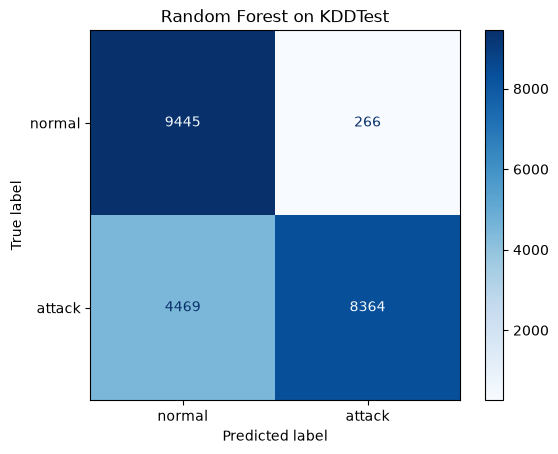

In [26]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_pred = rf_model.predict(x_test)

print(classification_report(y_test, y_pred, target_names=["normal", "attack"]))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["normal", "attack"]).plot(cmap="Blues")
plt.title("Random Forest on KDDTest")
plt.show()

precision    recall  f1-score   support

      normal       0.68      0.97      0.80      9711
      attack       0.97      0.65      0.78     12833

    accuracy                           0.79     22544
   macro avg       0.82      0.81      0.79     22544
weighted avg       0.84      0.79      0.79     22544

In [32]:
results = pd.DataFrame({
    "class": test["class"].astype(str).values,
    "pred": y_pred
})
attacks = results[results["class"] != "normal"]

summary = attacks.groupby("class")["pred"].agg(total="count", caught="sum")
summary["recall"] = (summary["caught"] / summary["total"]).round(2)
summary["seen_in_train"] = summary.index.isin(set(train["class"].astype(str)))

print(summary.sort_values("total", ascending=False))

                 total  caught  recall  seen_in_train
class                                                
neptune           4657    4655    1.00           True
guess_passwd      1231       0    0.00           True
mscan              996     409    0.41          False
warezmaster        944     291    0.31           True
apache2            737     499    0.68          False
satan              735     735    1.00           True
processtable       685       6    0.01          False
smurf              665     665    1.00           True
back               359     339    0.94           True
snmpguess          331       0    0.00          False
saint              319     313    0.98          False
mailbomb           293       0    0.00          False
snmpgetattack      178       0    0.00          False
portsweep          157     157    1.00           True
ipsweep            141     141    1.00           True
httptunnel         133      10    0.08          False
nmap                73      

total  caught  recall  seen_in_train
class                                                
neptune           4657    4655    1.00           True
guess_passwd      1231       0    0.00           True
mscan              996     409    0.41          False
warezmaster        944     291    0.31           True
apache2            737     499    0.68          False
satan              735     735    1.00           True
processtable       685       6    0.01          False
smurf              665     665    1.00           True
back               359     339    0.94           True
snmpguess          331       0    0.00          False
saint              319     313    0.98          False
mailbomb           293       0    0.00          False
snmpgetattack      178       0    0.00          False
portsweep          157     157    1.00           True
ipsweep            141     141    1.00           True
httptunnel         133      10    0.08          False
nmap                73      73    1.00           True
pod                 41      38    0.93           True
buffer_overflow     20       3    0.15           True
multihop            18       2    0.11           True
named               17       1    0.06          False
ps                  15       2    0.13          False
sendmail            14       0    0.00          False
xterm               13       3    0.23          False
rootkit             13       0    0.00           True
teardrop            12      12    1.00           True
xlock                9       0    0.00          False
land                 7       3    0.43           True
xsnoop               4       1    0.25          False
ftp_write            3       1    0.33           True
phf                  2       1    0.50           True
loadmodule           2       0    0.00           True
perl                 2       1    0.50           True
udpstorm             2       2    1.00          False
sqlattack            2       1    0.50          False
worm                 2       0    0.00          False
imap                 1       0    0.00           True